# Resultados de Traduccion WikiText-103 (selected 1000)

Analisis de los resultados del pipeline de traduccion EN->ES ejecutado sobre los 1,000 articulos
seleccionados del corpus WikiText-103 train.raw.

## Contenido
1. Resumen ejecutivo
2. Pipeline y modelos
3. Volumen y cobertura
4. Calidad (scores de evaluacion)
5. Problemas y fallos
6. Tiempos de ejecucion
7. Costos
8. Conclusiones y recomendaciones

In [9]:
import json
from pathlib import Path
from collections import Counter
from datetime import datetime

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

plt.rcParams.update({"figure.dpi": 120, "figure.figsize": (12, 5)})

PIPE_FILE = Path("../output/wikitext/wikitext-103-raw.wiki.train.selected_1000_pipeline_260620_235838.json")
ARTS_FILE = Path("../output/wikitext/wikitext-103-raw.wiki.train.selected_1000_260620_235838.json")
LOG_FILE = Path("../output/wikitext/translation_260618_015112.log")

with open(PIPE_FILE, encoding="utf-8") as f:
    pipe_data = json.load(f)
with open(ARTS_FILE, encoding="utf-8") as f:
    arts_data = json.load(f)

pipeline = pipe_data["pipeline"]
summary = pipe_data["summary"]
articles = arts_data["payload"][0]["data"]

print(f"Pipeline file: {PIPE_FILE.name}")
print(f"Articles file: {ARTS_FILE.name}")
print(f"Generated: {pipe_data['generated_at']}")
print(f"Articles: {len(pipeline):,}")

Pipeline file: wikitext-103-raw.wiki.train.selected_1000_pipeline_260620_235838.json
Articles file: wikitext-103-raw.wiki.train.selected_1000_260620_235838.json
Generated: 2026-06-20
Articles: 1,000


## 1. Resumen ejecutivo

In [10]:
# Calcular metricas clave
n_total = len(pipeline)
n_with_spanish = sum(1 for a in articles if a.get("spanish", {}).get("text", "").strip())
n_review_ok = sum(1 for p in pipeline if p.get("review") is not None)
n_eval_ok = sum(1 for p in pipeline if p.get("evaluation") is not None)
n_3_cands = sum(1 for p in pipeline if len(p.get("candidates", [])) == 3)
n_2_cands = sum(1 for p in pipeline if len(p.get("candidates", [])) == 2)

scores_all = [p["evaluation"]["overall_score"] for p in pipeline if p.get("evaluation")]
avg_score = sum(scores_all) / len(scores_all) if scores_all else 0

total_cost = summary["total_cost_usd"]["total"]
total_tokens = summary["total_tokens"]["total_tokens"]

print("=" * 65)
print("RESUMEN EJECUTIVO — Pipeline de Traduccion WikiText-103")
print("=" * 65)
print(f"Articulos procesados:       {n_total:>6,}")
print(f"Traducciones completadas:   {n_with_spanish:>6,}  ({n_with_spanish/n_total*100:.1f}%)")
print(f"Reviews completados:        {n_review_ok:>6,}  ({n_review_ok/n_total*100:.1f}%)")
print(f"Evaluaciones completadas:   {n_eval_ok:>6,}  ({n_eval_ok/n_total*100:.1f}%)")
print(f"Con 3 traductores:          {n_3_cands:>6,}  ({n_3_cands/n_total*100:.1f}%)")
print(f"Con 2 traductores:          {n_2_cands:>6,}  ({n_2_cands/n_total*100:.1f}%)")
print(f"Score promedio (overall):   {avg_score:>9.1f} / 100")
print(f"Tokens totales:             {total_tokens:>10,}")
print(f"Costo total:                ${total_cost:>9.2f} USD")
print(f"Costo promedio/articulo:    ${total_cost/n_total:>9.4f} USD")
print("=" * 65)

RESUMEN EJECUTIVO — Pipeline de Traduccion WikiText-103
Articulos procesados:        1,000
Traducciones completadas:    1,000  (100.0%)
Reviews completados:           993  (99.3%)
Evaluaciones completadas:      995  (99.5%)
Con 3 traductores:             981  (98.1%)
Con 2 traductores:              19  (1.9%)
Score promedio (overall):        95.9 / 100
Tokens totales:             70,917,901
Costo total:                $   104.54 USD
Costo promedio/articulo:    $   0.1045 USD


## 2. Pipeline y modelos

El pipeline tiene 3 stages + metadata:
- **Stage 1 (3 traductores):** Cada articulo se traduce por 3 modelos independientes
- **Stage 2 (reviewer):** Un modelo superior critica y genera la version final por consenso
- **Stage 3 (evaluador):** Evalua la traduccion final con metricas + verificacion programatica
- **Metadata:** Genera titulo, keywords, resumen, clasificacion

In [11]:
# Modelos utilizados
translator_models = Counter()
for p in pipeline:
    for c in p.get("candidates", []):
        translator_models[c.get("model", "?")] += 1

reviewer_models = Counter()
for p in pipeline:
    rev = p.get("review")
    if rev:
        reviewer_models[rev.get("model", "?")] += 1

eval_models = Counter()
for p in pipeline:
    ev = p.get("evaluation")
    if ev:
        eval_models[ev.get("model", "?")] += 1

print("MODELOS DEL PIPELINE")
print("=" * 65)
print("\nStage 1 — Traductores (candidatos):")
for m, c in translator_models.most_common():
    short = m.split(":")[-1]
    provider = m.split(":")[0] if ":" in m else "?"
    pct = c / n_total * 100
    print(f"  {short:<45} ({provider:<8}) {c:>5} arts ({pct:.1f}%)")

print(f"\nStage 2 — Reviewer:")
for m, c in reviewer_models.most_common():
    print(f"  {m}: {c} reviews ({c/n_total*100:.1f}%)")
print(f"  Sin review: {n_total - n_review_ok} ({(n_total - n_review_ok)/n_total*100:.1f}%)")

print(f"\nStage 3 — Evaluador:")
for m, c in eval_models.most_common():
    print(f"  {m}: {c} evaluaciones ({c/n_total*100:.1f}%)")
print(f"  Sin evaluacion: {n_total - n_eval_ok} ({(n_total - n_eval_ok)/n_total*100:.1f}%)")

MODELOS DEL PIPELINE

Stage 1 — Traductores (candidatos):
  dataset-frontierscience-gpt41mini             (azure   )  1000 arts (100.0%)
  9b                                            (ollama  )  1000 arts (100.0%)
  dataset-frontierscience-mistral-large         (foundry )   981 arts (98.1%)

Stage 2 — Reviewer:
  azure:dataset-frontierscience-gpt41: 993 reviews (99.3%)
  Sin review: 7 (0.7%)

Stage 3 — Evaluador:
  azure:dataset-frontierscience-gpt41mini: 995 evaluaciones (99.5%)
  Sin evaluacion: 5 (0.5%)


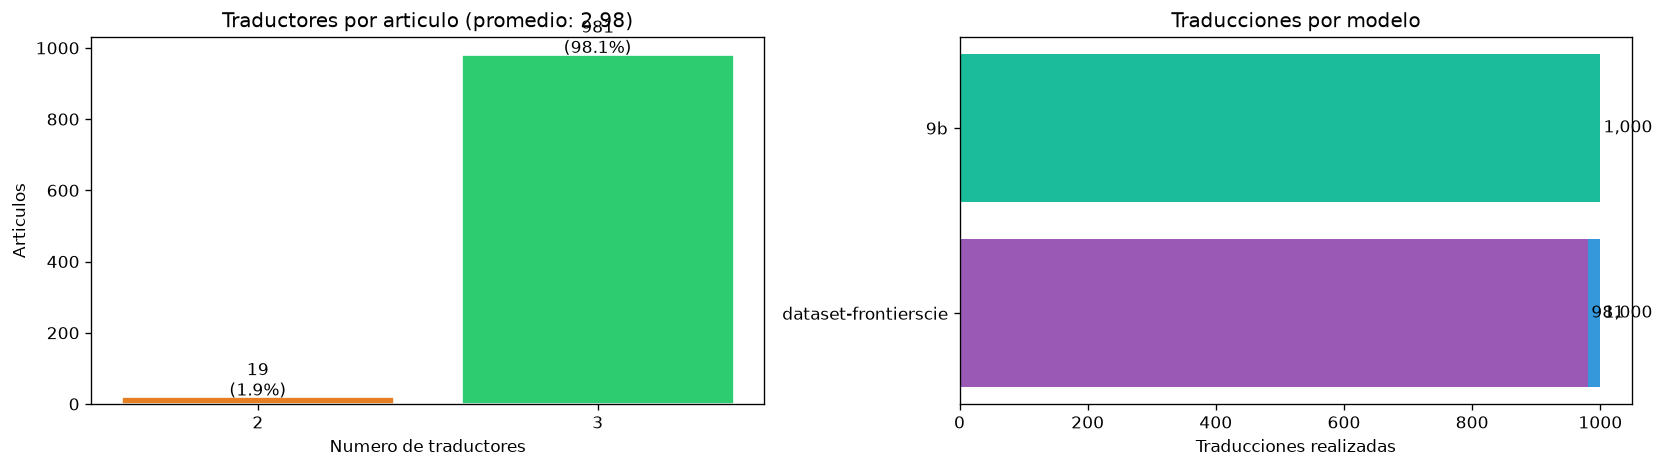

In [12]:
# Promedio de traductores por articulo
cands_per_art = [len(p.get("candidates", [])) for p in pipeline]
avg_cands = sum(cands_per_art) / len(cands_per_art)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Distribucion de candidatos por articulo
ax = axes[0]
cand_counts = Counter(cands_per_art)
labels = sorted(cand_counts.keys())
values = [cand_counts[l] for l in labels]
colors = ["#2ecc71" if l == 3 else "#e67e22" if l == 2 else "#e74c3c" for l in labels]
ax.bar(labels, values, color=colors, edgecolor="white")
ax.set_xlabel("Numero de traductores")
ax.set_ylabel("Articulos")
ax.set_title(f"Traductores por articulo (promedio: {avg_cands:.2f})")
for l, v in zip(labels, values):
    ax.text(l, v + 5, f"{v}\n({v/n_total*100:.1f}%)", ha="center", fontsize=10)
ax.set_xticks(labels)

# Participacion por modelo traductor
ax = axes[1]
short_names = [m.split(":")[-1][:20] for m in translator_models.keys()]
counts = list(translator_models.values())
bars = ax.barh(short_names, counts, color=["#3498db", "#9b59b6", "#1abc9c"])
ax.set_xlabel("Traducciones realizadas")
ax.set_title("Traducciones por modelo")
for bar, count in zip(bars, counts):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f"{count:,}", va="center", fontsize=10)

plt.tight_layout()
plt.show()

## 3. Volumen y cobertura

In [13]:
# Calcular chars del texto original y traducido
data_rows = []
for i, (art, pip) in enumerate(zip(articles, pipeline)):
    en_text = art.get("english", {}).get("text", "")
    es_text = art.get("spanish", {}).get("text", "")
    ev = pip.get("evaluation") or {}
    tu = pip.get("token_usage", {})
    cost = tu.get("cost_usd", {}).get("total_usd", 0) if tu else 0
    
    en_words = len(en_text.split()) if en_text else 0
    es_words = len(es_text.split()) if es_text else 0
    en_chars = len(en_text) if en_text else 0
    es_chars = len(es_text) if es_text else 0
    
    n_cands = len(pip.get("candidates", []))
    has_review = pip.get("review") is not None
    has_eval = pip.get("evaluation") is not None
    
    classification = art.get("english", {}).get("classification", "unknown")
    
    data_rows.append({
        "id": i + 1,
        "en_words": en_words,
        "es_words": es_words,
        "en_chars": en_chars,
        "es_chars": es_chars,
        "n_candidates": n_cands,
        "has_review": has_review,
        "has_eval": has_eval,
        "char_ratio": ev.get("char_ratio", 0),
        "overall_score": ev.get("overall_score", None),
        "clarity": ev.get("clarity", None),
        "fidelity": ev.get("fidelity", None),
        "completeness": ev.get("completeness", None),
        "fluency": ev.get("fluency", None),
        "cost_usd": cost,
        "classification": classification,
    })

df = pd.DataFrame(data_rows)

print("VOLUMEN DE TRADUCCION")
print("=" * 65)
print(f"Palabras originales (EN):    {df['en_words'].sum():>12,}")
print(f"Palabras traducidas (ES):    {df['es_words'].sum():>12,}")
print(f"Caracteres originales (EN):  {df['en_chars'].sum():>12,}")
print(f"Caracteres traducidos (ES):  {df['es_chars'].sum():>12,}")
print(f"Ratio palabras ES/EN:        {df['es_words'].sum()/df['en_words'].sum():>12.3f}")
print(f"Ratio chars ES/EN:           {df['es_chars'].sum()/df['en_chars'].sum():>12.3f}")
print()

# Clasificacion tematica
cls_counts = df["classification"].value_counts()
print("CLASIFICACION TEMATICA (generada por el pipeline)")
print("-" * 50)
for cls, cnt in cls_counts.head(15).items():
    print(f"  {cls:<30} {cnt:>4} ({cnt/n_total*100:.1f}%)")

VOLUMEN DE TRADUCCION
Palabras originales (EN):       3,268,319
Palabras traducidas (ES):       3,014,603
Caracteres originales (EN):    17,634,690
Caracteres traducidos (ES):    18,427,292
Ratio palabras ES/EN:               0.922
Ratio chars ES/EN:                  1.045

CLASIFICACION TEMATICA (generada por el pipeline)
--------------------------------------------------
  history                         284 (28.4%)
  entertainment                   260 (26.0%)
  biography                       106 (10.6%)
  science                         101 (10.1%)
  sports                           96 (9.6%)
  video game                       45 (4.5%)
  technology                       23 (2.3%)
  politics                         18 (1.8%)
  medicine                         12 (1.2%)
  literature                       10 (1.0%)
  novel                             9 (0.9%)
  other                             9 (0.9%)
  Science                           6 (0.6%)
  education                        

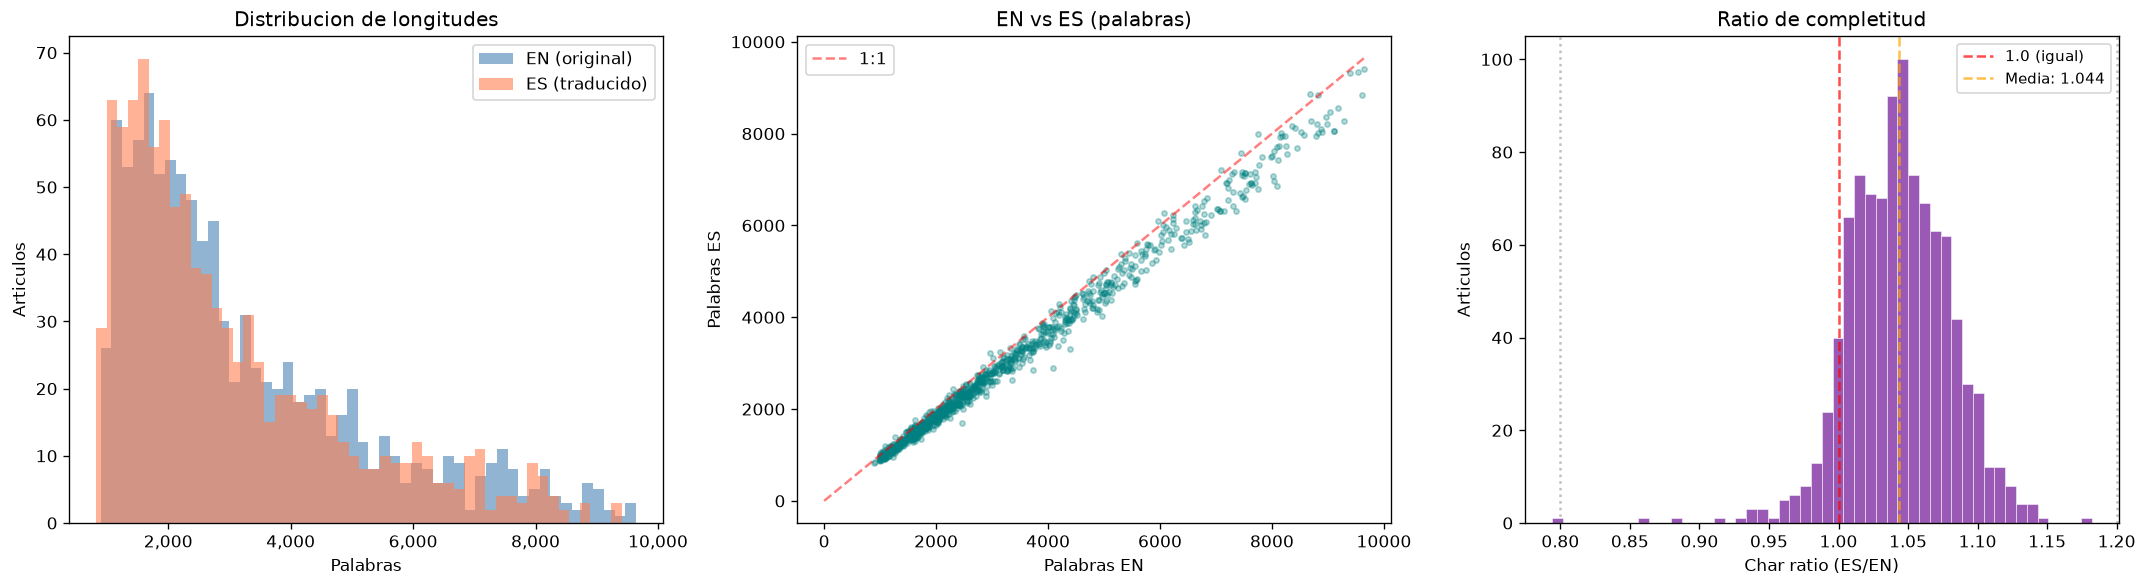

Char ratio: media=1.044, mediana=1.044, min=0.794, max=1.182
Truncados (<0.8):  1
Posiblemente truncados (<0.9): 3
Expandidos (>1.1): 55


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Distribucion de palabras originales vs traducidas
ax = axes[0]
ax.hist(df["en_words"], bins=50, alpha=0.6, label="EN (original)", color="steelblue")
ax.hist(df["es_words"], bins=50, alpha=0.6, label="ES (traducido)", color="coral")
ax.set_xlabel("Palabras")
ax.set_ylabel("Articulos")
ax.set_title("Distribucion de longitudes")
ax.legend()
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x:,.0f}"))

# Scatter: EN words vs ES words
ax = axes[1]
ax.scatter(df["en_words"], df["es_words"], alpha=0.3, s=10, color="teal")
max_w = max(df["en_words"].max(), df["es_words"].max())
ax.plot([0, max_w], [0, max_w], "r--", alpha=0.5, label="1:1")
ax.set_xlabel("Palabras EN")
ax.set_ylabel("Palabras ES")
ax.set_title("EN vs ES (palabras)")
ax.legend()

# Char ratio distribution
ax = axes[2]
ratios = df[df["char_ratio"] > 0]["char_ratio"]
ax.hist(ratios, bins=50, color="#9b59b6", edgecolor="white", linewidth=0.3)
ax.axvline(1.0, color="red", linestyle="--", alpha=0.7, label="1.0 (igual)")
ax.axvline(ratios.mean(), color="orange", linestyle="--", alpha=0.7, label=f"Media: {ratios.mean():.3f}")
ax.axvline(0.8, color="gray", linestyle=":", alpha=0.5)
ax.axvline(1.2, color="gray", linestyle=":", alpha=0.5)
ax.set_xlabel("Char ratio (ES/EN)")
ax.set_ylabel("Articulos")
ax.set_title("Ratio de completitud")
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Stats
print(f"Char ratio: media={ratios.mean():.3f}, mediana={ratios.median():.3f}, "
      f"min={ratios.min():.3f}, max={ratios.max():.3f}")
print(f"Truncados (<0.8):  {(ratios < 0.8).sum()}")
print(f"Posiblemente truncados (<0.9): {(ratios < 0.9).sum()}")
print(f"Expandidos (>1.1): {(ratios > 1.1).sum()}")

## 4. Calidad (scores de evaluacion)

In [15]:
df_eval = df[df["has_eval"]].copy()
metrics = ["clarity", "fidelity", "completeness", "fluency", "overall_score"]

print("METRICAS DE CALIDAD")
print("=" * 75)
print(f"Articulos evaluados: {len(df_eval)} / {n_total}")
print()
print(f"{'Metrica':<16} {'Media':>7} {'Mediana':>8} {'Min':>5} {'Max':>5} {'Std':>6} {'<90':>5} {'<80':>5}")
print("-" * 75)
for m in metrics:
    vals = df_eval[m].dropna()
    below_90 = (vals < 90).sum()
    below_80 = (vals < 80).sum()
    print(f"{m:<16} {vals.mean():>7.1f} {vals.median():>8.0f} {vals.min():>5.0f} {vals.max():>5.0f} "
          f"{vals.std():>6.1f} {below_90:>5} {below_80:>5}")

METRICAS DE CALIDAD
Articulos evaluados: 995 / 1000

Metrica            Media  Mediana   Min   Max    Std   <90   <80
---------------------------------------------------------------------------
clarity             97.7       98    90    98    1.0     0     0
fidelity            97.6       98    70    99    1.3     2     1
completeness        99.8      100    70   100    1.6     3     2
fluency             97.5       98    92    99    1.0     0     0
overall_score       95.9       96    70    98    2.0     5     1


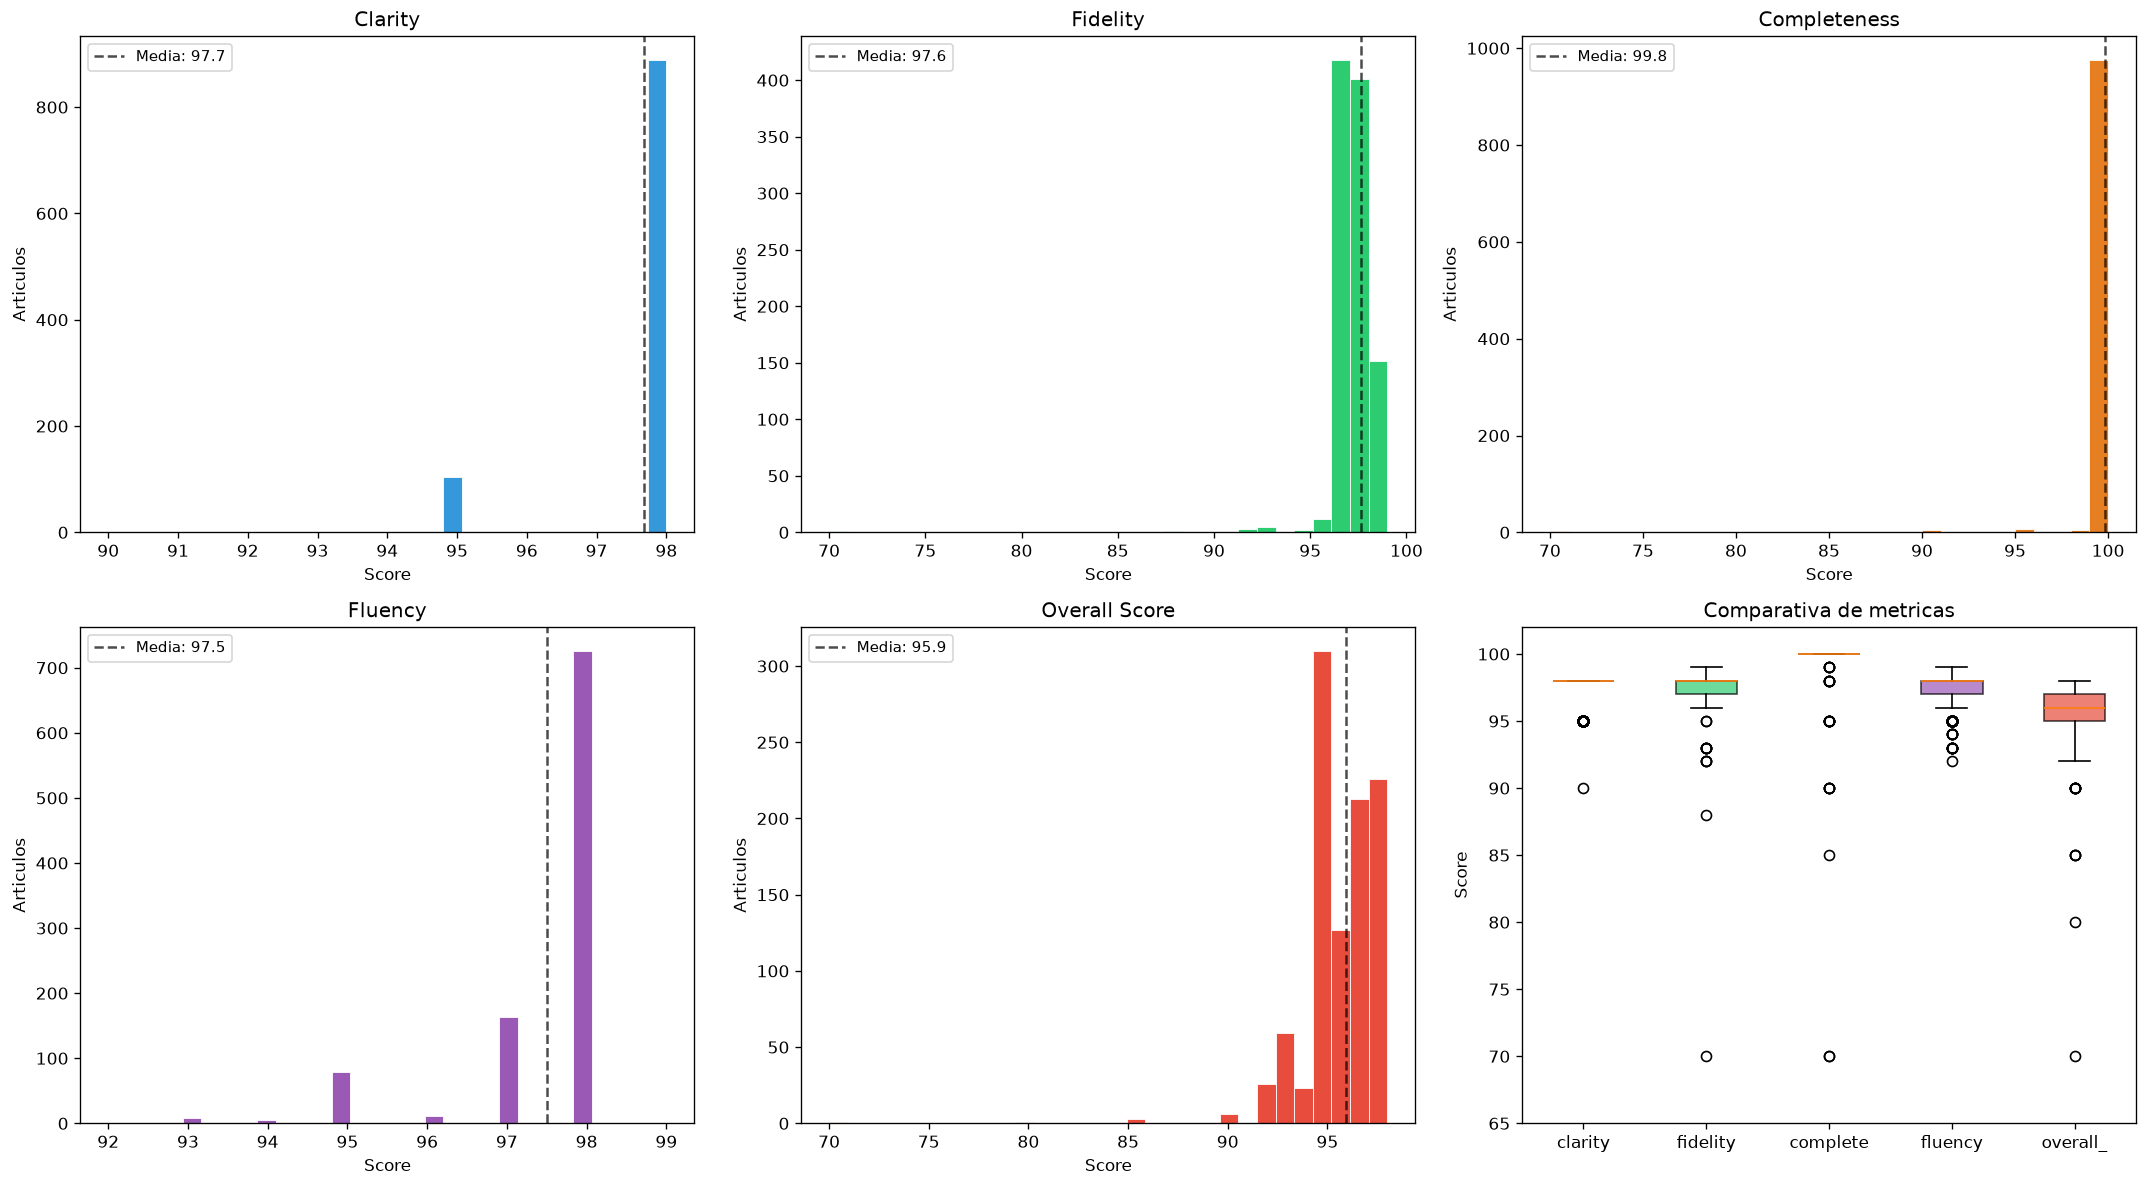

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

colors = ["#3498db", "#2ecc71", "#e67e22", "#9b59b6", "#e74c3c"]

for i, m in enumerate(metrics):
    ax = axes[i]
    vals = df_eval[m].dropna()
    ax.hist(vals, bins=30, color=colors[i], edgecolor="white", linewidth=0.5)
    ax.axvline(vals.mean(), color="black", linestyle="--", alpha=0.7,
               label=f"Media: {vals.mean():.1f}")
    ax.set_xlabel("Score")
    ax.set_ylabel("Articulos")
    ax.set_title(m.replace("_", " ").title())
    ax.legend(fontsize=9)

# Boxplot comparativo en el ultimo panel
ax = axes[5]
bp_data = [df_eval[m].dropna().values for m in metrics]
bp = ax.boxplot(bp_data, patch_artist=True)
ax.set_xticks(range(1, len(metrics) + 1))
ax.set_xticklabels([m[:8] for m in metrics])
for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax.set_ylabel("Score")
ax.set_title("Comparativa de metricas")
ax.set_ylim(65, 102)

plt.tight_layout()
plt.show()

In [17]:
# Distribucion de overall_score por rangos
bins = [0, 70, 80, 85, 90, 95, 101]
labels = ["<70", "70-79", "80-84", "85-89", "90-94", "95-100"]
df_eval["score_bin"] = pd.cut(df_eval["overall_score"], bins=bins, labels=labels, right=False)

score_dist = df_eval["score_bin"].value_counts().sort_index()
print("DISTRIBUCION DE OVERALL SCORE")
print("-" * 50)
for label, count in score_dist.items():
    bar = "#" * (count // 5)
    pct = count / len(df_eval) * 100
    print(f"  {label:>7}: {count:>4} ({pct:>5.1f}%)  {bar}")

# Articulos con score bajo (< 90)
low_score = df_eval[df_eval["overall_score"] < 90].sort_values("overall_score")
print(f"\nArticulos con score < 90: {len(low_score)}")
if len(low_score) > 0:
    print(f"{'ID':>4} {'Score':>6} {'Clarity':>8} {'Fidelity':>9} {'Compl.':>7} {'Fluency':>8} {'CharRatio':>10}")
    for _, row in low_score.iterrows():
        print(f"{row['id']:>4} {row['overall_score']:>6.0f} {row['clarity']:>8.0f} {row['fidelity']:>9.0f} "
              f"{row['completeness']:>7.0f} {row['fluency']:>8.0f} {row['char_ratio']:>10.3f}")

DISTRIBUCION DE OVERALL SCORE
--------------------------------------------------
      <70:    0 (  0.0%)  
    70-79:    1 (  0.1%)  
    80-84:    1 (  0.1%)  
    85-89:    3 (  0.3%)  
    90-94:  114 ( 11.5%)  ######################
   95-100:  876 ( 88.0%)  ###############################################################################################################################################################################

Articulos con score < 90: 5
  ID  Score  Clarity  Fidelity  Compl.  Fluency  CharRatio
 226     70       95        70      70       95      0.972
 766     80       90        88      70       92      0.794
 385     85       98        98     100       97      0.988
 293     85       98        92      95       97      0.998
 558     85       98        97      85       98      1.071


## 5. Problemas y fallos

In [18]:
print("RESUMEN DE PROBLEMAS")
print("=" * 70)

# 1. Mistral failures
mistral_missing = sum(
    1 for p in pipeline
    if not any("mistral" in c.get("model", "") for c in p.get("candidates", []))
)
print(f"\n1. MISTRAL LARGE — fallos de traduccion")
print(f"   Articulos sin candidato Mistral: {mistral_missing} ({mistral_missing/n_total*100:.1f}%)")
print(f"   Causa: Content filtering de Azure (HTTP 400) en articulos con")
print(f"   contenido historico-belico, y fallas sistematicas de no-traduccion.")

# 2. Review failures
no_review = [i for i, p in enumerate(pipeline) if p.get("review") is None]
print(f"\n2. REVIEW (Stage 2) — fallos")
print(f"   Articulos sin review: {len(no_review)} ({len(no_review)/n_total*100:.1f}%)")
print(f"   IDs: {[i+1 for i in no_review]}")
print(f"   Causa: Content filtering Azure o timeout en merge de secciones.")
print(f"   Impacto: Se uso fallback a candidates[0] sin revision por consenso.")

# 3. Evaluation failures
no_eval = [i for i, p in enumerate(pipeline) if p.get("evaluation") is None]
print(f"\n3. EVALUACION (Stage 3) — fallos")
print(f"   Articulos sin evaluacion: {len(no_eval)} ({len(no_eval)/n_total*100:.1f}%)")
print(f"   IDs: {[i+1 for i in no_eval]}")

# 4. Non-translation issue (candidates returned in English)
print(f"\n4. CANDIDATOS NO TRADUCIDOS (devueltos en ingles)")
print(f"   Segun errores.md, en los primeros 388 articulos:")
print(f"   - Mistral Large: 183 arts (47.2%) devolvieron texto en ingles")
print(f"   - GPT-4.1 mini:  47 arts (12.1%) devolvieron texto en ingles")
print(f"   - Qwen 3.5 9B:    0 arts  (0%)   siempre tradujo correctamente")
print(f"   Impacto: Reviewer con menos candidatos reales para fusionar.")
print(f"   Ningun articulo quedo sin traduccion (Qwen siempre funciono).")

# 5. Articles with both issues
both_failed = set(no_review) & set(no_eval)
print(f"\n5. ARTICULOS CON MULTIPLES FALLOS")
print(f"   Sin review NI evaluacion: {len(both_failed)}")
if both_failed:
    print(f"   IDs: {sorted([i+1 for i in both_failed])}")

RESUMEN DE PROBLEMAS

1. MISTRAL LARGE — fallos de traduccion
   Articulos sin candidato Mistral: 19 (1.9%)
   Causa: Content filtering de Azure (HTTP 400) en articulos con
   contenido historico-belico, y fallas sistematicas de no-traduccion.

2. REVIEW (Stage 2) — fallos
   Articulos sin review: 7 (0.7%)
   IDs: [301, 385, 481, 494, 548, 649, 817]
   Causa: Content filtering Azure o timeout en merge de secciones.
   Impacto: Se uso fallback a candidates[0] sin revision por consenso.

3. EVALUACION (Stage 3) — fallos
   Articulos sin evaluacion: 5 (0.5%)
   IDs: [53, 301, 467, 787, 873]

4. CANDIDATOS NO TRADUCIDOS (devueltos en ingles)
   Segun errores.md, en los primeros 388 articulos:
   - Mistral Large: 183 arts (47.2%) devolvieron texto en ingles
   - GPT-4.1 mini:  47 arts (12.1%) devolvieron texto en ingles
   - Qwen 3.5 9B:    0 arts  (0%)   siempre tradujo correctamente
   Impacto: Reviewer con menos candidatos reales para fusionar.
   Ningun articulo quedo sin traduccion (Qw

In [19]:
# Detalle de articulos fallidos
print("DETALLE DE ARTICULOS CON FALLOS")
print("=" * 90)
print(f"{'Art':>4} {'Cands':>5} {'Review':>7} {'Eval':>5} {'Score':>6} {'Cost':>8} {'Hint (primeros chars)'}")
print("-" * 90)

failed_ids = set(no_review) | set(no_eval)
for idx in sorted(failed_ids):
    p = pipeline[idx]
    cands = p.get("candidates", [])
    rev = p.get("review")
    ev = p.get("evaluation")
    tu = p.get("token_usage", {})
    cost = tu.get("cost_usd", {}).get("total_usd", 0) if tu else 0
    score = ev["overall_score"] if ev else "-"
    
    hint = ""
    if cands:
        txt = cands[0].get("text", "")[:60]
        hint = txt.split("\n")[0][:55]
    
    rev_str = "OK" if rev else "FAIL"
    eval_str = "OK" if ev else "FAIL"
    
    print(f"{idx+1:>4} {len(cands):>5} {rev_str:>7} {eval_str:>5} {str(score):>6} ${cost:>7.3f} {hint}")

DETALLE DE ARTICULOS CON FALLOS
 Art Cands  Review  Eval  Score     Cost Hint (primeros chars)
------------------------------------------------------------------------------------------
  53     3      OK  FAIL      - $  0.237 = Transformador =
 301     2    FAIL  FAIL      - $  0.023 Aborto forzado de Feng Jianmei
 385     2    FAIL    OK     85 $  0.091 = Abd al-Rahman ibn Muhammad ibn al-Ash'ath =
 467     3      OK  FAIL      - $  0.105 = Mindaugas =
 481     3    FAIL    OK     96 $  0.011 Controversia por el arresto de Faeq al-Mir
 494     3    FAIL    OK     97 $  0.154 Colin James Farrell (nacido el 31 de mayo de 1976) es u
 548     2    FAIL    OK     95 $  0.014 = Tío David =
 649     2    FAIL    OK     98 $  0.061 Antonio Ezequiel Cárdenas Guillén (5 de marzo de 1962 –
 787     3      OK  FAIL      - $  0.133 Oscar Palmer Robertson (nacido el 24 de noviembre de 19
 817     2    FAIL    OK     95 $  0.098 = Kylie Platt =
 873     3      OK  FAIL      - $  0.089 Secret of Eve

## 6. Tiempos de ejecucion

In [20]:
# Extraer timestamps
art_times = []
for i, p in enumerate(pipeline):
    ts = []
    for c in p.get("candidates", []):
        t = c.get("translated_at")
        if t: ts.append(t)
    rev = p.get("review")
    if rev:
        t = rev.get("reviewed_at")
        if t: ts.append(t)
    ev = p.get("evaluation")
    if ev:
        t = ev.get("evaluated_at")
        if t: ts.append(t)
    if ts:
        ts.sort()
        art_times.append({"id": i + 1, "first": ts[0], "last": ts[-1]})

if art_times:
    fmt = "%Y-%m-%dT%H:%M:%S.%f"
    t_start = datetime.strptime(art_times[0]["first"][:26], fmt)
    t_end = datetime.strptime(art_times[-1]["last"][:26], fmt)
    total_delta = t_end - t_start
    total_hours = total_delta.total_seconds() / 3600
    
    # Per-article durations
    durations = []
    for at in art_times:
        try:
            t0 = datetime.strptime(at["first"][:26], fmt)
            t1 = datetime.strptime(at["last"][:26], fmt)
            durations.append((t1 - t0).total_seconds())
        except:
            pass
    
    print("TIEMPOS DE EJECUCION")
    print("=" * 65)
    print(f"Inicio:              {t_start.strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Fin:                 {t_end.strftime('%Y-%m-%d %H:%M:%S')}")
    print(f"Duracion total:      {total_delta} ({total_hours:.1f} horas)")
    print(f"Promedio/articulo:   {total_delta.total_seconds()/n_total:.0f} seg ({total_delta.total_seconds()/n_total/60:.1f} min)")
    print()
    
    if durations:
        dur = np.array(durations)
        print(f"Duracion por articulo (procesamiento):")
        print(f"  Media:   {dur.mean():.0f} seg ({dur.mean()/60:.1f} min)")
        print(f"  Mediana: {np.median(dur):.0f} seg ({np.median(dur)/60:.1f} min)")
        print(f"  Min:     {dur.min():.0f} seg")
        print(f"  Max:     {dur.max():.0f} seg ({dur.max()/60:.1f} min)")
        print(f"  P95:     {np.percentile(dur, 95):.0f} seg ({np.percentile(dur, 95)/60:.1f} min)")

TIEMPOS DE EJECUCION
Inicio:              2026-06-15 23:10:22
Fin:                 2026-06-20 23:58:32
Duracion total:      5 days, 0:48:09.954077 (120.8 horas)
Promedio/articulo:   435 seg (7.2 min)

Duracion por articulo (procesamiento):
  Media:   279 seg (4.6 min)
  Mediana: 225 seg (3.8 min)
  Min:     67 seg
  Max:     1096 seg (18.3 min)
  P95:     657 seg (10.9 min)


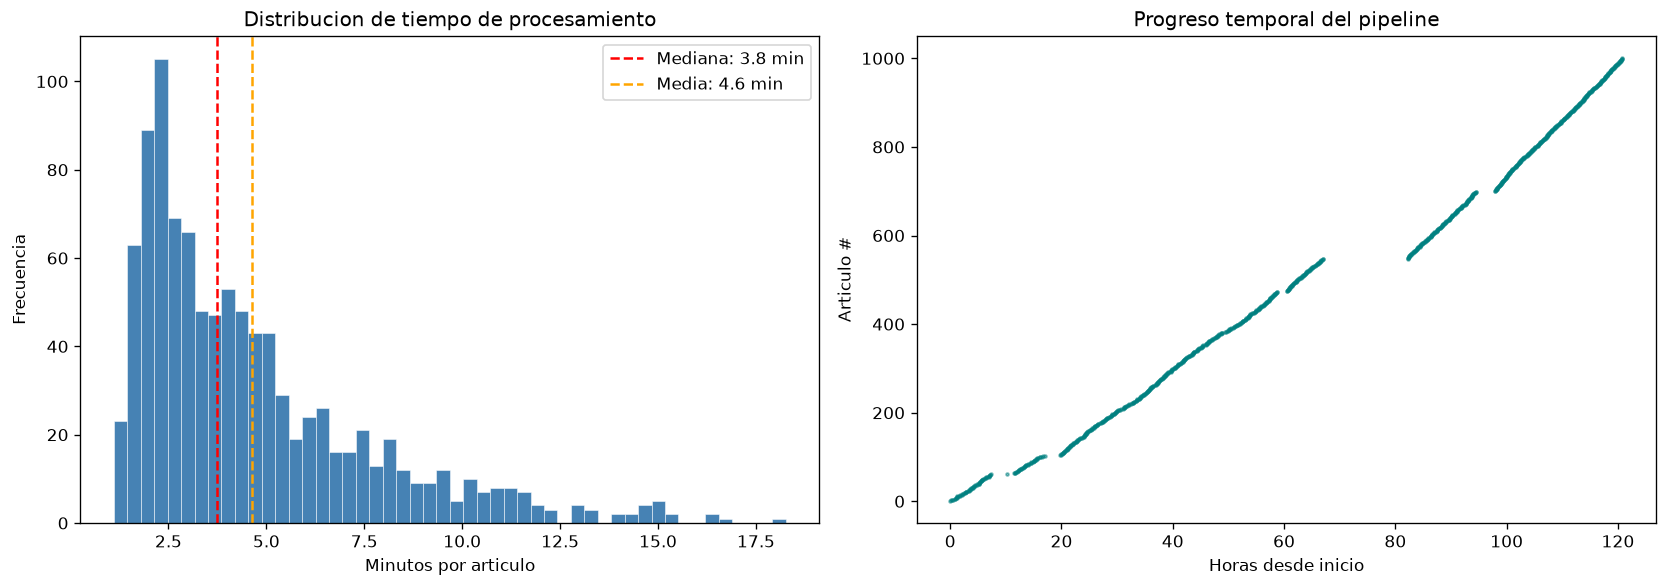

In [21]:
if durations:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Histograma de duracion por articulo
    ax = axes[0]
    dur_min = np.array(durations) / 60
    ax.hist(dur_min, bins=50, color="steelblue", edgecolor="white", linewidth=0.3)
    ax.axvline(np.median(dur_min), color="red", linestyle="--",
               label=f"Mediana: {np.median(dur_min):.1f} min")
    ax.axvline(np.mean(dur_min), color="orange", linestyle="--",
               label=f"Media: {np.mean(dur_min):.1f} min")
    ax.set_xlabel("Minutos por articulo")
    ax.set_ylabel("Frecuencia")
    ax.set_title("Distribucion de tiempo de procesamiento")
    ax.legend()
    
    # Timeline: articulo vs timestamp
    ax = axes[1]
    times_parsed = []
    for at in art_times:
        try:
            t = datetime.strptime(at["last"][:26], fmt)
            hours_from_start = (t - t_start).total_seconds() / 3600
            times_parsed.append((at["id"], hours_from_start))
        except:
            pass
    if times_parsed:
        ids, hrs = zip(*times_parsed)
        ax.scatter(hrs, ids, s=3, alpha=0.5, color="teal")
        ax.set_xlabel("Horas desde inicio")
        ax.set_ylabel("Articulo #")
        ax.set_title("Progreso temporal del pipeline")
    
    plt.tight_layout()
    plt.show()

## 7. Costos

In [22]:
cost_breakdown = summary["total_cost_usd"]

print("DESGLOSE DE COSTOS")
print("=" * 65)

# Stage 1
s1 = cost_breakdown["stage_1_translation"]
s1_total = sum(v for v in s1.values())
print(f"\nStage 1 — Traduccion (3 modelos):          ${s1_total:>8.2f} ({s1_total/total_cost*100:.1f}%)")
for model, cost in s1.items():
    short = model.split(":")[-1]
    print(f"  {short:<42} ${cost:>8.2f}")

# Stage 2
s2 = cost_breakdown["stage_2_review"]
print(f"\nStage 2 — Review (GPT-4.1):                ${s2:>8.2f} ({s2/total_cost*100:.1f}%)")

# Stage 3
s3 = cost_breakdown["stage_3_evaluation"]
print(f"Stage 3 — Evaluacion (GPT-4.1 mini):        ${s3:>8.2f} ({s3/total_cost*100:.1f}%)")

# Metadata
sm = cost_breakdown["metadata"]
print(f"Metadata (titulo, keywords, clasificacion):  ${sm:>8.2f} ({sm/total_cost*100:.1f}%)")

print(f"\n{'TOTAL':>47} ${total_cost:>8.2f}")
print(f"{'Costo por articulo':>47} ${total_cost/n_total:>8.4f}")

DESGLOSE DE COSTOS

Stage 1 — Traduccion (3 modelos):          $   20.00 (19.1%)
  dataset-frontierscience-gpt41mini          $    9.01
  dataset-frontierscience-mistral-large      $   10.98
  9b                                         $    0.00

Stage 2 — Review (GPT-4.1):                $   76.87 (73.5%)
Stage 3 — Evaluacion (GPT-4.1 mini):        $    3.76 (3.6%)
Metadata (titulo, keywords, clasificacion):  $    3.91 (3.7%)

                                          TOTAL $  104.54
                             Costo por articulo $  0.1045


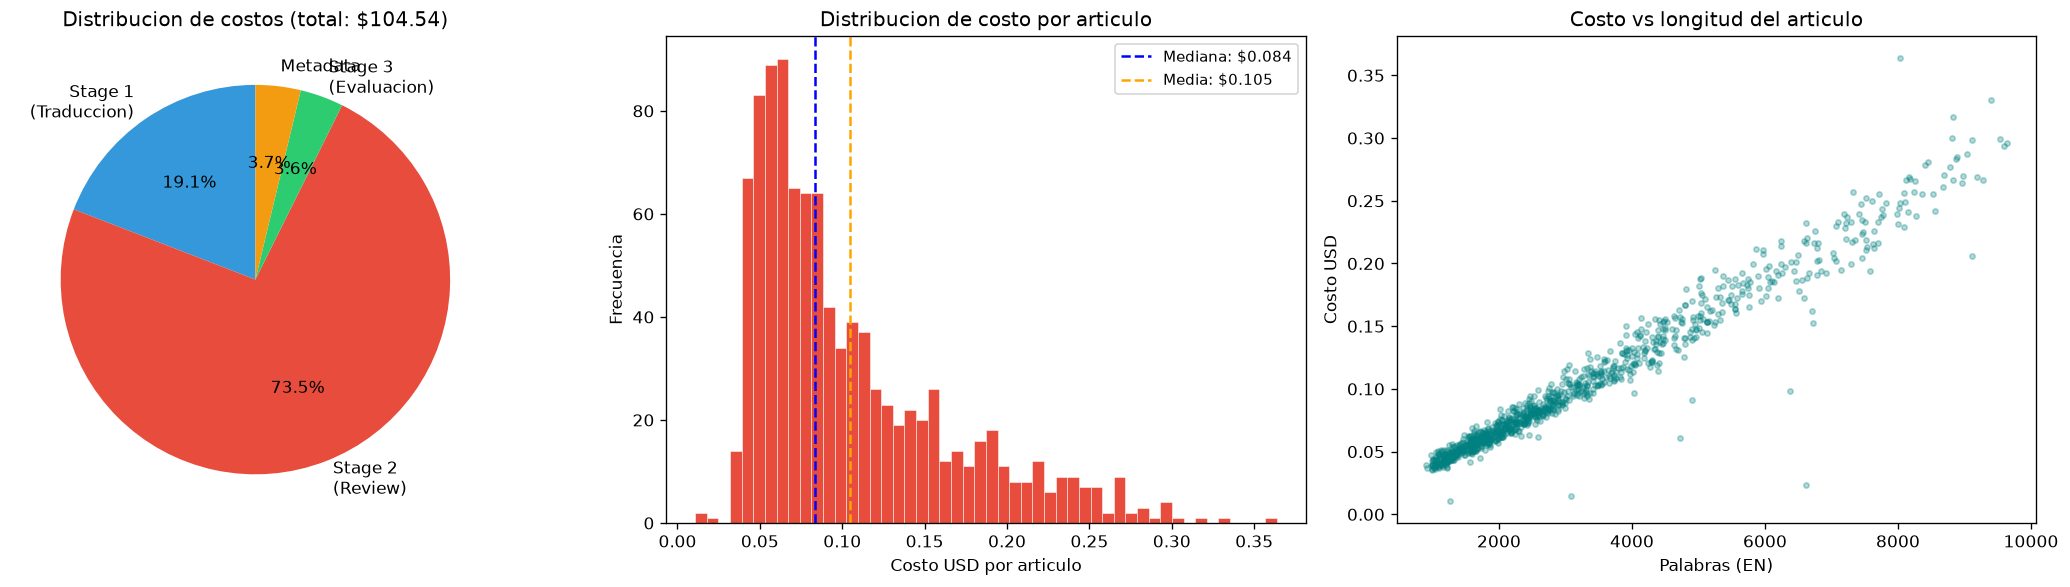


PERCENTILES DE COSTO POR ARTICULO
----------------------------------------
  P 5: $0.0432
  P10: $0.0478
  P25: $0.0599
  P50: $0.0836
  P75: $0.1331
  P90: $0.1945
  P95: $0.2333
  P99: $0.2836


In [23]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Pie chart de costos por stage
ax = axes[0]
stage_labels = ["Stage 1\n(Traduccion)", "Stage 2\n(Review)", "Stage 3\n(Evaluacion)", "Metadata"]
stage_costs = [s1_total, s2, s3, sm]
stage_colors = ["#3498db", "#e74c3c", "#2ecc71", "#f39c12"]
wedges, texts, autotexts = ax.pie(
    stage_costs, labels=stage_labels, autopct="%1.1f%%",
    colors=stage_colors, startangle=90
)
ax.set_title(f"Distribucion de costos (total: ${total_cost:.2f})")

# Histograma de costo por articulo
ax = axes[1]
ax.hist(df["cost_usd"], bins=50, color="#e74c3c", edgecolor="white", linewidth=0.3)
ax.axvline(df["cost_usd"].median(), color="blue", linestyle="--",
           label=f"Mediana: ${df['cost_usd'].median():.3f}")
ax.axvline(df["cost_usd"].mean(), color="orange", linestyle="--",
           label=f"Media: ${df['cost_usd'].mean():.3f}")
ax.set_xlabel("Costo USD por articulo")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribucion de costo por articulo")
ax.legend(fontsize=9)

# Costo vs palabras
ax = axes[2]
ax.scatter(df["en_words"], df["cost_usd"], alpha=0.3, s=10, color="teal")
ax.set_xlabel("Palabras (EN)")
ax.set_ylabel("Costo USD")
ax.set_title("Costo vs longitud del articulo")

plt.tight_layout()
plt.show()

# Percentiles de costo
print("\nPERCENTILES DE COSTO POR ARTICULO")
print("-" * 40)
for p in [5, 10, 25, 50, 75, 90, 95, 99]:
    val = df["cost_usd"].quantile(p / 100)
    print(f"  P{p:>2}: ${val:.4f}")

In [24]:
# Tokens totales
tok = summary["total_tokens"]
print("CONSUMO DE TOKENS")
print("=" * 50)
print(f"Prompt tokens:      {tok['prompt_tokens']:>14,}")
print(f"Completion tokens:  {tok['completion_tokens']:>14,}")
print(f"Total tokens:       {tok['total_tokens']:>14,}")
print(f"Ratio output/input: {tok['completion_tokens']/tok['prompt_tokens']:.2f}")
print(f"\nTokens por articulo (promedio): {tok['total_tokens']/n_total:,.0f}")
print(f"Costo por millon de tokens:     ${total_cost / (tok['total_tokens']/1_000_000):.2f}")

CONSUMO DE TOKENS
Prompt tokens:          51,018,864
Completion tokens:      19,899,037
Total tokens:           70,917,901
Ratio output/input: 0.39

Tokens por articulo (promedio): 70,918
Costo por millon de tokens:     $1.47


## 8. Comparativa con test run anterior

In [25]:
# Load test run (62 articles = test.raw) for comparison
test_pipe_file = Path("../output/wikitext/tests/wikitext-103-raw.wiki.test_pipeline_260612_032122.json")
if test_pipe_file.exists():
    with open(test_pipe_file, encoding="utf-8") as f:
        test_data = json.load(f)
    test_pipeline = test_data.get("pipeline", [])
    test_summary = test_data.get("summary", {})
    
    test_scores = [p["evaluation"]["overall_score"] 
                   for p in test_pipeline if p.get("evaluation")]
    test_cost = test_summary.get("total_cost_usd", {}).get("total", 0)
    test_tokens = test_summary.get("total_tokens", {}).get("total_tokens", 0)
    test_n = len(test_pipeline)
    
    print("COMPARATIVA: TEST RUN (62 arts) vs PRODUCCION (1000 arts)")
    print("=" * 70)
    print(f"{'Metrica':<30} {'Test (62)':>15} {'Prod (1000)':>15} {'Delta':>10}")
    print("-" * 70)
    
    test_avg = sum(test_scores)/len(test_scores) if test_scores else 0
    prod_avg = sum(scores_all)/len(scores_all) if scores_all else 0
    print(f"{'Score promedio':<30} {test_avg:>15.1f} {prod_avg:>15.1f} {prod_avg-test_avg:>+10.1f}")
    
    test_cpp = test_cost/test_n if test_n else 0
    prod_cpp = total_cost/n_total
    print(f"{'Costo/articulo (USD)':<30} ${test_cpp:>14.4f} ${prod_cpp:>14.4f} ${prod_cpp-test_cpp:>+9.4f}")
    
    test_tpa = test_tokens/test_n if test_n else 0
    prod_tpa = total_tokens/n_total
    print(f"{'Tokens/articulo':<30} {test_tpa:>15,.0f} {prod_tpa:>15,.0f} {prod_tpa-test_tpa:>+10,.0f}")
    
    print(f"{'Costo total (USD)':<30} ${test_cost:>14.2f} ${total_cost:>14.2f}")
    print(f"{'Tokens totales':<30} {test_tokens:>15,} {total_tokens:>15,}")
else:
    print("No se encontro el archivo de test run para comparar.")

COMPARATIVA: TEST RUN (62 arts) vs PRODUCCION (1000 arts)
Metrica                              Test (62)     Prod (1000)      Delta
----------------------------------------------------------------------
Score promedio                            96.0            95.9       -0.0
Costo/articulo (USD)           $        0.1183 $        0.1045 $  -0.0138
Tokens/articulo                         79,442          70,918     -8,525
Costo total (USD)              $          7.34 $        104.54
Tokens totales                       4,925,434      70,917,901


## 9. Calidad por clasificacion tematica

In [26]:
# Score promedio por clasificacion
df_with_score = df[df["overall_score"].notna()].copy()
cls_stats = df_with_score.groupby("classification").agg(
    n=("id", "count"),
    score_avg=("overall_score", "mean"),
    score_min=("overall_score", "min"),
    cost_avg=("cost_usd", "mean"),
    cost_total=("cost_usd", "sum"),
).sort_values("n", ascending=False)

print("CALIDAD Y COSTO POR TEMA")
print("=" * 80)
print(f"{'Tema':<25} {'N':>4} {'Score avg':>10} {'Score min':>10} {'$/art':>8} {'$ total':>9}")
print("-" * 80)
for tema, row in cls_stats.head(15).iterrows():
    print(f"{tema[:25]:<25} {row['n']:>4} {row['score_avg']:>10.1f} {row['score_min']:>10.0f} "
          f"${row['cost_avg']:>7.4f} ${row['cost_total']:>8.2f}")

CALIDAD Y COSTO POR TEMA
Tema                         N  Score avg  Score min    $/art   $ total
--------------------------------------------------------------------------------
history                   283.0       95.5         70 $ 0.1104 $   31.23
entertainment             260.0       95.8         80 $ 0.0878 $   22.82
biography                 106.0       96.1         90 $ 0.1125 $   11.92
science                   101.0       96.4         90 $ 0.1028 $   10.38
sports                    95.0       96.3         90 $ 0.1168 $   11.09
video game                44.0       96.3         93 $ 0.1031 $    4.54
technology                22.0       96.1         92 $ 0.1255 $    2.76
politics                  17.0       96.2         93 $ 0.1109 $    1.88
medicine                  12.0       97.3         95 $ 0.1457 $    1.75
literature                10.0       96.2         95 $ 0.1098 $    1.10
other                      9.0       95.7         92 $ 0.0927 $    0.83
novel                     

## 10. Conclusiones y recomendaciones

In [27]:
print("""
CONCLUSIONES
============

1. COBERTURA: 1,000/1,000 articulos traducidos (100%). Aunque 7 articulos
   no pasaron por review y 5 no fueron evaluados, TODOS tienen traduccion
   al espanol gracias al fallback a candidates[0].

2. CALIDAD: Score promedio de 95.9/100. El 88% de articulos tiene score
   >= 95. Solo 5 articulos (0.5%) tienen score < 90. Completeness es
   la metrica mas alta (99.8 avg), lo que indica que el fix de
   truncamiento funciono correctamente.

3. MODELOS: Qwen 3.5:9b (Ollama local, $0) fue el traductor mas
   confiable (100% exito). Mistral Large fallo en 19 articulos
   (content filtering Azure) y no tradujo en ~47% de los primeros
   388 articulos. GPT-4.1 mini tuvo 12.1% de no-traducciones.

4. COSTOS: $104.54 total. El 73.5% del costo fue Stage 2 (review)
   porque usa GPT-4.1 (modelo mas caro). Stage 1 (traduccion) fue
   solo 19.1% del costo. Ollama (Qwen) aporto traducciones gratuitas.

5. TIEMPOS: ~120 horas (5 dias) de ejecucion. Promedio ~7 minutos
   por articulo incluyendo los 3 stages + metadata.

RECOMENDACIONES
===============

1. Reemplazar Mistral Large: con 47% de no-traducciones y 1.9% de
   content filtering, su aporte al consenso es debil. Considerar
   DeepSeek-V3 o un segundo modelo Ollama local.

2. Agregar validacion de idioma post-traduccion: detectar candidatos
   devueltos en ingles antes de enviarlos al reviewer.

3. Reducir costo del reviewer: Stage 2 domina el costo. Evaluar si
   GPT-4.1 mini puede hacer review aceptable (ahorraria ~$60).

4. Los 7+5 articulos con fallos parciales podrian reprocesarse
   individualmente para completar review/evaluacion.
""")


CONCLUSIONES

1. COBERTURA: 1,000/1,000 articulos traducidos (100%). Aunque 7 articulos
   no pasaron por review y 5 no fueron evaluados, TODOS tienen traduccion
   al espanol gracias al fallback a candidates[0].

2. CALIDAD: Score promedio de 95.9/100. El 88% de articulos tiene score
   >= 95. Solo 5 articulos (0.5%) tienen score < 90. Completeness es
   la metrica mas alta (99.8 avg), lo que indica que el fix de
   truncamiento funciono correctamente.

3. MODELOS: Qwen 3.5:9b (Ollama local, $0) fue el traductor mas
   confiable (100% exito). Mistral Large fallo en 19 articulos
   (content filtering Azure) y no tradujo en ~47% de los primeros
   388 articulos. GPT-4.1 mini tuvo 12.1% de no-traducciones.

4. COSTOS: $104.54 total. El 73.5% del costo fue Stage 2 (review)
   porque usa GPT-4.1 (modelo mas caro). Stage 1 (traduccion) fue
   solo 19.1% del costo. Ollama (Qwen) aporto traducciones gratuitas.

5. TIEMPOS: ~120 horas (5 dias) de ejecucion. Promedio ~7 minutos
   por articulo